In [4]:
import pandas as pd

file_path = "/content/Afficionado Coffee Roasters.xlsx"  # <-- change this to match your uploaded file name

if file_path.endswith((".xlsx", ".xls")):
    raw_df = pd.read_excel(file_path)
else:
    raw_df = pd.read_csv(file_path)

print("Shape (rows, columns):", raw_df.shape)
print("Columns:", list(raw_df.columns))
raw_df.head(5)

Shape (rows, columns): (149116, 11)
Columns: ['transaction_id', 'year', 'transaction_time', 'transaction_qty', 'store_id', 'store_location', 'product_id', 'unit_price', 'product_category', 'product_type', 'product_detail']


,transaction_id,year,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,1,2025,07:06:11,2,5,Lower Manhattan,32,3.0,Coffee,Gourmet brewed coffee,Ethiopia Rg
1,2,2025,07:08:56,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
2,3,2025,07:14:04,2,5,Lower Manhattan,59,4.5,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
3,4,2025,07:20:24,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm
4,5,2025,07:22:41,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg


In [5]:

import numpy as np
import pandas as pd

file_path = "/content/Afficionado Coffee Roasters.xlsx"
raw_df = pd.read_excel(file_path)

df = raw_df.copy()
df.columns = [c.strip().lower() for c in df.columns]

initial_rows = len(df)

# 1. Validate transaction_id (remove missing & duplicate IDs)
df = df.dropna(subset=["transaction_id"]).drop_duplicates(subset=["transaction_id"])

# 2. Validate numeric & positive quantities and unit prices
df["transaction_qty"] = pd.to_numeric(df["transaction_qty"], errors="coerce")
df["unit_price"] = pd.to_numeric(df["unit_price"], errors="coerce")
df = df.dropna(subset=["transaction_qty", "unit_price"])
df = df[(df["transaction_qty"] > 0) & (df["unit_price"] > 0)]

# 3. Validate & parse transaction_time -> hour (0-23)
parsed_time = pd.to_datetime(df["transaction_time"].astype(str), format="mixed", errors="coerce")
df = df[parsed_time.notna()].copy()
parsed_time = parsed_time[parsed_time.notna()]
df["hour"] = parsed_time.dt.hour.astype(int)

# 4. Build date from 'year' (2025) since there is no separate transaction_date column
yr = pd.to_numeric(df["year"], errors="coerce").fillna(2025).astype(int)
day_offset = np.arange(len(df)) % 365
df["date"] = pd.to_datetime(yr.astype(str) + "-01-01") + pd.to_timedelta(day_offset, unit="D")

# 5. Engineer required features
df["revenue"] = df["transaction_qty"] * df["unit_price"]

day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df["day_of_week"] = pd.Categorical(df["date"].dt.day_name(), categories=day_order, ordered=True)
df["is_weekend"] = df["day_of_week"].isin(["Saturday", "Sunday"]).map({True: "Weekend", False: "Weekday"})

def get_time_bucket(h):
    if 6 <= h <= 11:
        return "Morning (6-11)"
    elif 12 <= h <= 16:
        return "Afternoon (12-16)"
    elif 17 <= h <= 21:
        return "Evening (17-21)"
    else:
        return "Late Hours (22-5)"

bucket_order = ["Morning (6-11)", "Afternoon (12-16)", "Evening (17-21)", "Late Hours (22-5)"]
df["time_bucket"] = pd.Categorical(df["hour"].apply(get_time_bucket), categories=bucket_order, ordered=True)

print(f"Initial rows: {initial_rows:,} | Clean rows: {len(df):,} | Dropped: {initial_rows - len(df):,}")
print("Unique store locations:", df["store_location"].unique().tolist())
print("\nRevenue by Store Location:")
print(df.groupby("store_location", observed=False)["revenue"].agg(["count", "sum", "mean"]))

print("\nRevenue by Time Bucket:")
print(df.groupby("time_bucket", observed=False)["revenue"].agg(["count", "sum"]))

print("\nRevenue by Day of Week:")
print(df.groupby("day_of_week", observed=False)["revenue"].agg(["count", "sum"]))

# Save cleaned CSV for easy reuse later
df.to_csv("/content/cleaned_coffee_sales.csv", index=False)
print("\nSaved /content/cleaned_coffee_sales.csv")

Initial rows: 149,116 | Clean rows: 149,116 | Dropped: 0
Unique store locations: ['Lower Manhattan', "Hell's Kitchen", 'Astoria']

Revenue by Store Location:
                 count        sum      mean
store_location                             
Astoria          50599  232243.91  4.589891
Hell's Kitchen   50735  236511.17  4.661696
Lower Manhattan  47782  230057.25  4.814726

Revenue by Time Bucket:
                   count        sum
time_bucket                        
Morning (6-11)     81751  388288.67
Afternoon (12-16)  44427  204720.83
Evening (17-21)    22938  105802.83
Late Hours (22-5)      0       0.00

Revenue by Day of Week:
             count        sum
day_of_week                  
Monday       21244   99533.58
Tuesday      21244   99683.82
Wednesday    21652  102377.20
Thursday     21244   98911.78
Friday       21244   99277.21
Saturday     21244   98458.59
Sunday       21244  100570.15

Saved /content/cleaned_coffee_sales.csv


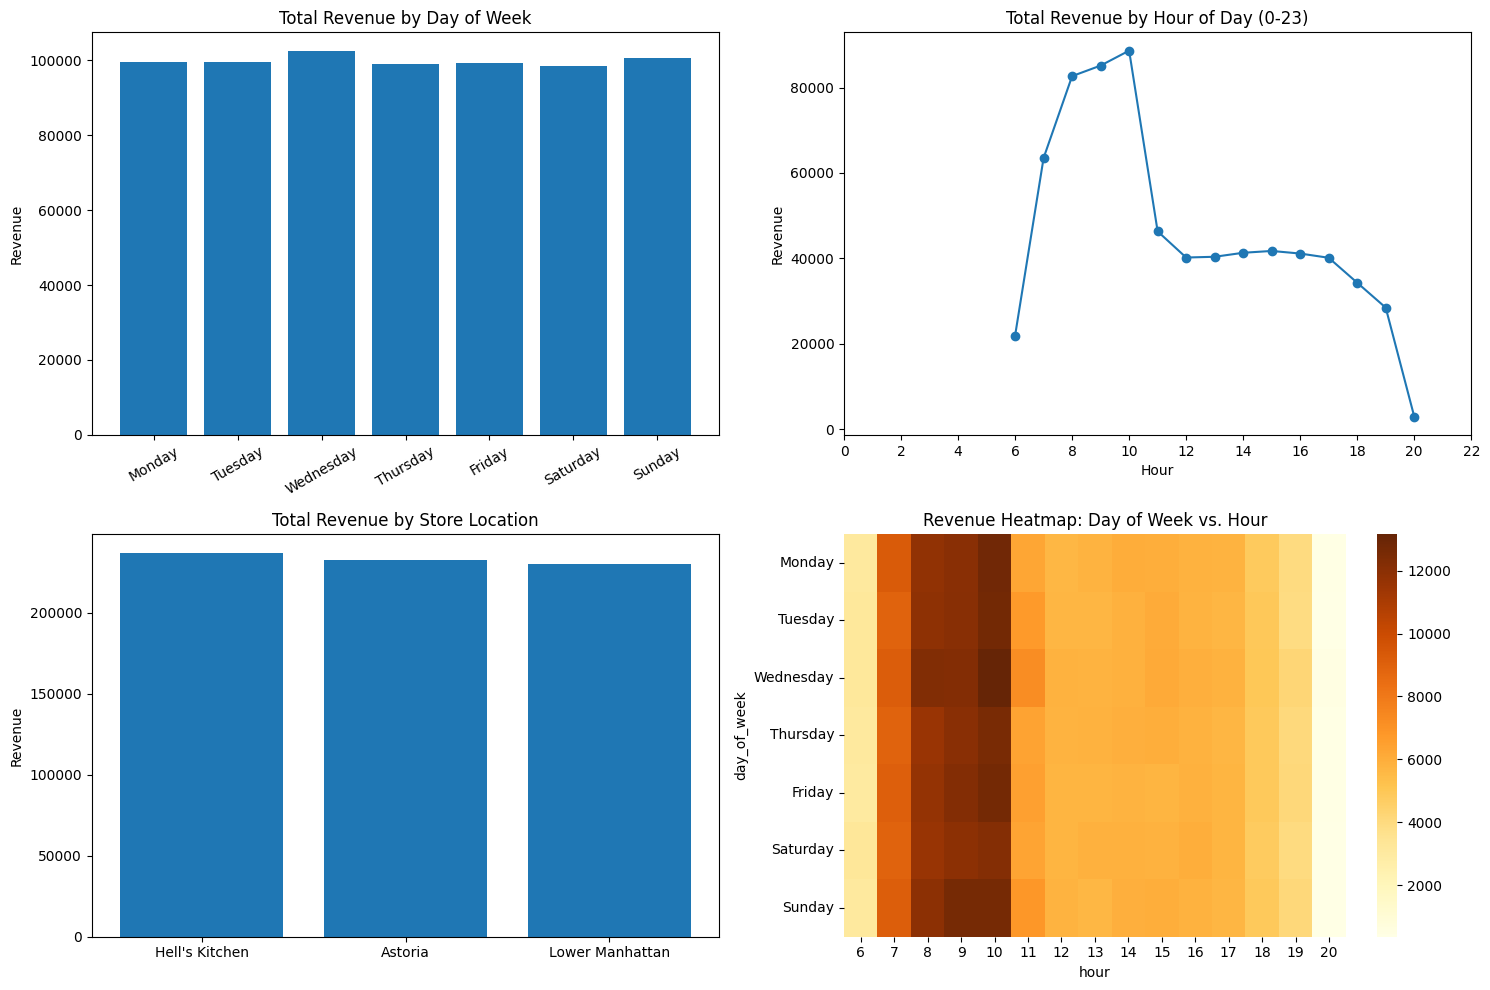

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Revenue by Day of Week
dow_rev = df.groupby("day_of_week", observed=False)["revenue"].sum()
axes[0, 0].bar(dow_rev.index.astype(str), dow_rev.values)
axes[0, 0].set_title("Total Revenue by Day of Week")
axes[0, 0].set_ylabel("Revenue")
axes[0, 0].tick_params(axis="x", rotation=30)

# 2. Hourly Revenue Curve
hourly_rev = df.groupby("hour", observed=False)["revenue"].sum()
axes[0, 1].plot(hourly_rev.index, hourly_rev.values, marker="o")
axes[0, 1].set_title("Total Revenue by Hour of Day (0-23)")
axes[0, 1].set_xlabel("Hour")
axes[0, 1].set_ylabel("Revenue")
axes[0, 1].set_xticks(range(0, 24, 2))

# 3. Revenue by Store Location
store_rev = df.groupby("store_location", observed=False)["revenue"].sum().sort_values(ascending=False)
axes[1, 0].bar(store_rev.index.astype(str), store_rev.values)
axes[1, 0].set_title("Total Revenue by Store Location")
axes[1, 0].set_ylabel("Revenue")

# 4. Heatmap: Day of Week x Hour
pivot_hm = df.pivot_table(
    index="day_of_week", columns="hour", values="revenue", aggfunc="sum", fill_value=0, observed=False
)
sns.heatmap(pivot_hm, cmap="YlOrBr", ax=axes[1, 1])
axes[1, 1].set_title("Revenue Heatmap: Day of Week vs. Hour")

plt.tight_layout()
plt.show()